In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

c:\Users\hp\anaconda3\lib\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [3]:
df=pd.read_csv(r"E:\smec\ford.csv")

In [4]:
df.head()

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
0,Fiesta,2017,12000,Automatic,15944,Petrol,150,57.7,1.0
1,Focus,2018,14000,Manual,9083,Petrol,150,57.7,1.0
2,Focus,2017,13000,Manual,12456,Petrol,150,57.7,1.0
3,Fiesta,2019,17500,Manual,10460,Petrol,145,40.3,1.5
4,Fiesta,2019,16500,Automatic,1482,Petrol,145,48.7,1.0


In [5]:
df.describe()

,year,price,mileage,tax,mpg,engineSize
count,17966.000000,17966.000000,17966.000000,17966.000000,17966.000000,17966.000000
mean,2016.866470,12279.534844,23362.608761,113.329456,57.906980,1.350807
std,2.050336,4741.343657,19472.054349,62.012456,10.125696,0.432367
min,1996.000000,495.000000,1.000000,0.000000,20.800000,0.000000
25%,2016.000000,8999.000000,9987.000000,30.000000,52.300000,1.000000
50%,2017.000000,11291.000000,18242.500000,145.000000,58.900000,1.200000
75%,2018.000000,15299.000000,31060.000000,145.000000,65.700000,1.500000
max,2060.000000,54995.000000,177644.000000,580.000000,201.800000,5.000000


In [6]:
df.shape

(17966, 9)

In [7]:
df.isnull().sum()


model           0
year            0
price           0
transmission    0
mileage         0
fuelType        0
tax             0
mpg             0
engineSize      0
dtype: int64

In [8]:
df.duplicated().sum()

154

In [9]:
df.drop_duplicates(inplace=True)

In [10]:
df.duplicated().sum()

0

In [11]:
df.head()

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
0,Fiesta,2017,12000,Automatic,15944,Petrol,150,57.7,1.0
1,Focus,2018,14000,Manual,9083,Petrol,150,57.7,1.0
2,Focus,2017,13000,Manual,12456,Petrol,150,57.7,1.0
3,Fiesta,2019,17500,Manual,10460,Petrol,145,40.3,1.5
4,Fiesta,2019,16500,Automatic,1482,Petrol,145,48.7,1.0


<Axes: xlabel='price', ylabel='Count'>

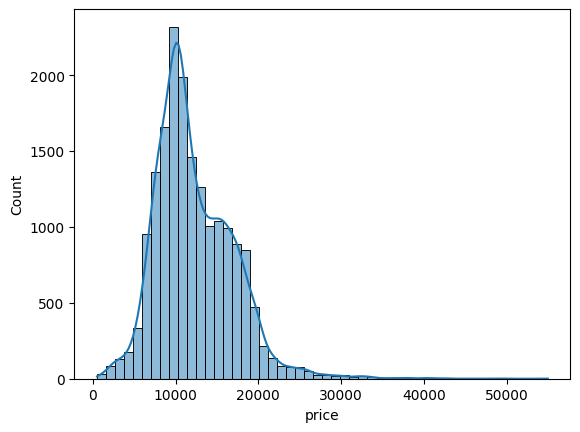

In [12]:
sns.histplot(data=df,x='price',kde=True,bins=50)

In [13]:
corr=df.corr(numeric_only=True)
print(corr)

                year     price   mileage       tax       mpg  engineSize
year        1.000000  0.635715 -0.708690  0.297183 -0.021702   -0.137582
price       0.635715  1.000000 -0.530483  0.405969 -0.346263    0.411451
mileage    -0.708690 -0.530483  1.000000 -0.257543  0.117697    0.214692
tax         0.297183  0.405969 -0.257543  1.000000 -0.502343    0.185358
mpg        -0.021702 -0.346263  0.117697 -0.502343  1.000000   -0.262239
engineSize -0.137582  0.411451  0.214692  0.185358 -0.262239    1.000000


<Axes: >

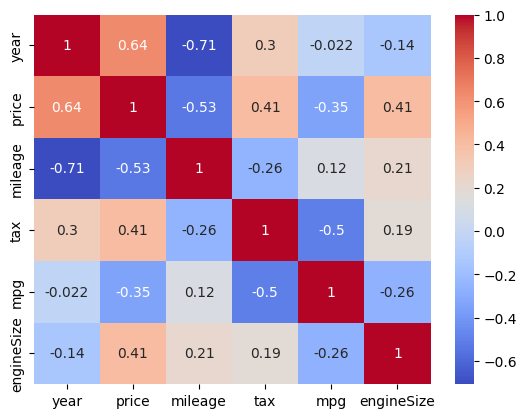

In [14]:
sns.heatmap(corr,annot=True,cmap="coolwarm")

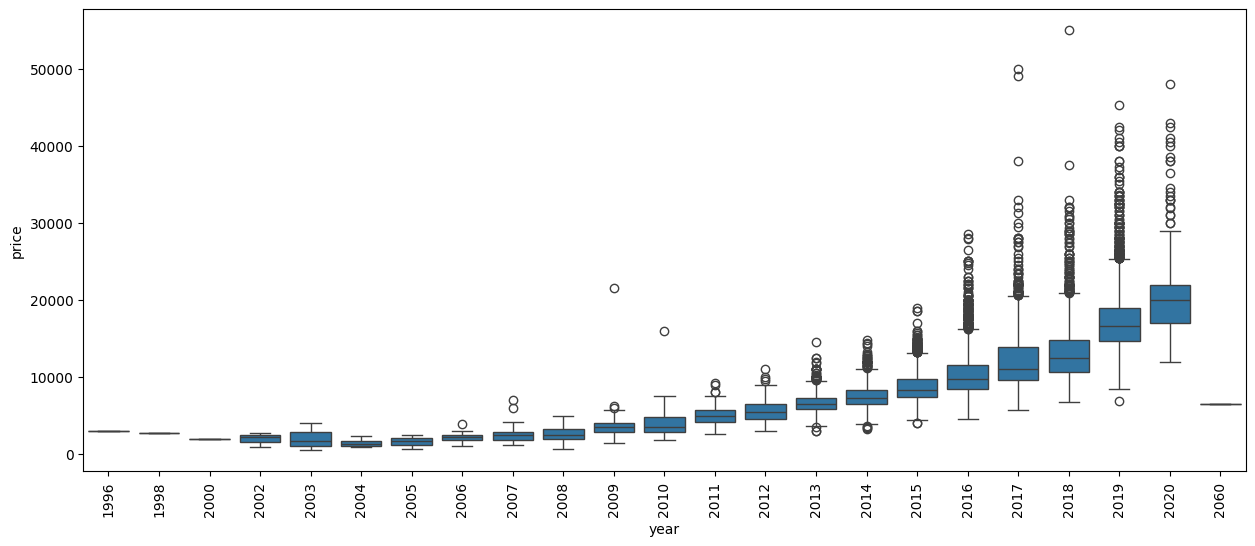

In [15]:
plt.figure(figsize=(15,6))
sns.boxplot(data=df,x="year",y="price")
plt.xticks(rotation=90)
plt.show()

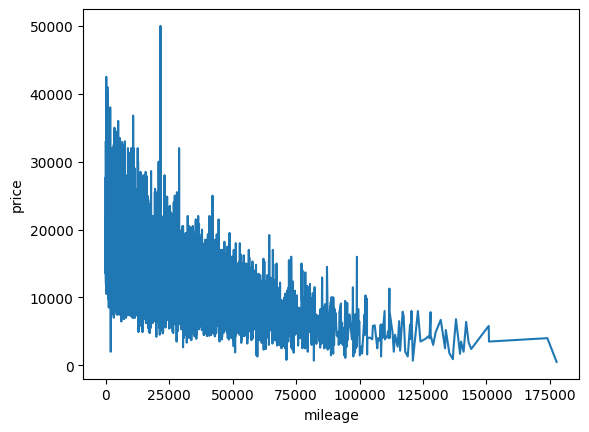

In [16]:
sns.lineplot(data=df.sort_values("mileage"),x="mileage",y="price",estimator="mean",errorbar=None)
plt.xlabel("mileage")
plt.ylabel("price")
plt.show()

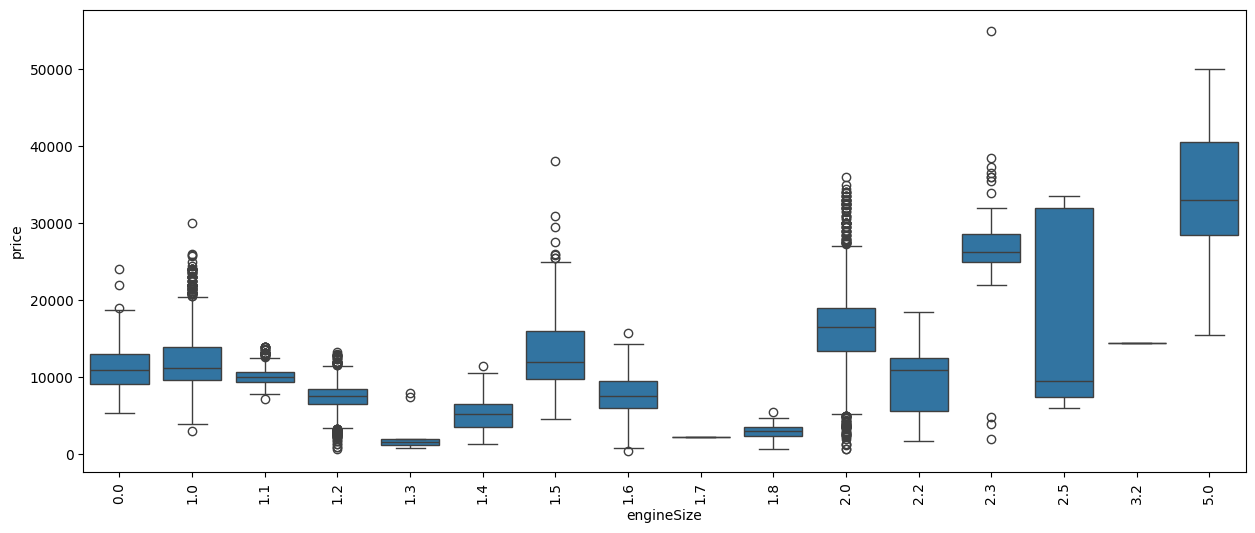

In [17]:
plt.figure(figsize=(15,6))
sns.boxplot(data=df,x="engineSize",y="price")
plt.xticks(rotation=90)
plt.show()

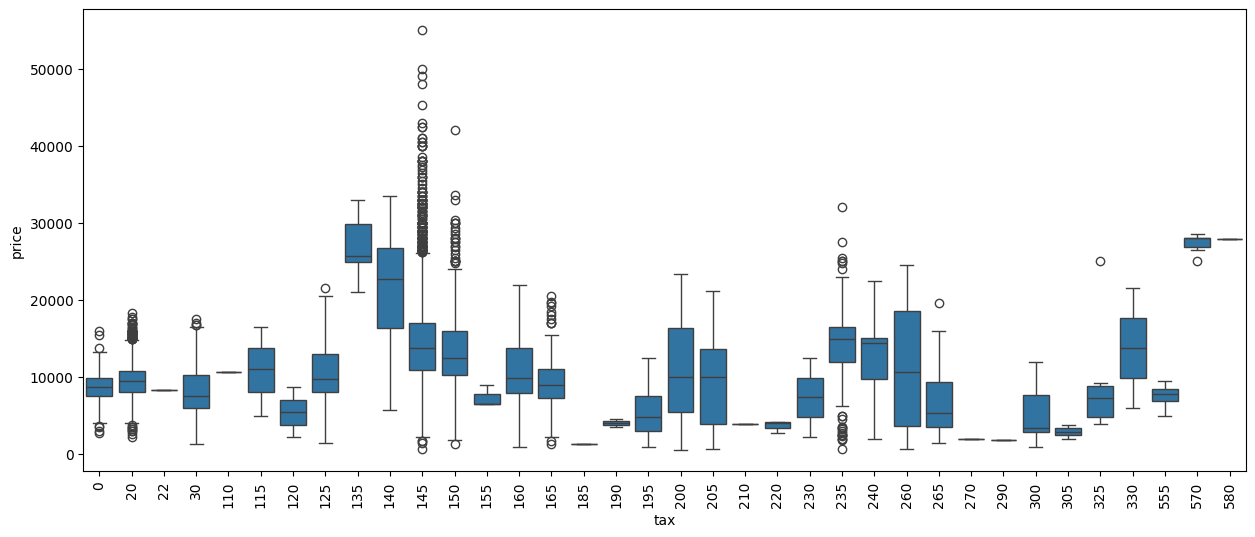

In [18]:
plt.figure(figsize=(15,6))
sns.boxplot(data=df,x="tax",y="price")
plt.xticks(rotation=90)
plt.show()

<Axes: xlabel='transmission', ylabel='price'>

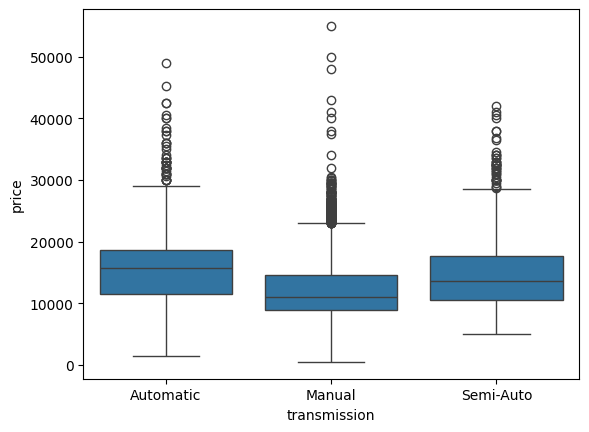

In [19]:
sns.boxplot(data=df,x='transmission',y="price")

In [20]:
max(df["year"])

2060

In [21]:
df=df[df["year"]<2026]

In [22]:
max(df["year"])

2020

In [23]:
rf=max(df["year"])

In [24]:
df['car_age']=rf-df["year"]

In [25]:
df.head()

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize,car_age
0,Fiesta,2017,12000,Automatic,15944,Petrol,150,57.7,1.0,3
1,Focus,2018,14000,Manual,9083,Petrol,150,57.7,1.0,2
2,Focus,2017,13000,Manual,12456,Petrol,150,57.7,1.0,3
3,Fiesta,2019,17500,Manual,10460,Petrol,145,40.3,1.5,1
4,Fiesta,2019,16500,Automatic,1482,Petrol,145,48.7,1.0,1


In [26]:
corr=df.corr(numeric_only=True)
print(corr)

                year     price   mileage       tax       mpg  engineSize  \
year        1.000000  0.645236 -0.719636  0.299192 -0.020195   -0.139458   
price       0.645236  1.000000 -0.530433  0.406112 -0.346401    0.411476   
mileage    -0.719636 -0.530433  1.000000 -0.257712  0.117849    0.214698   
tax         0.299192  0.406112 -0.257712  1.000000 -0.502282    0.185360   
mpg        -0.020195 -0.346401  0.117849 -0.502282  1.000000   -0.262246   
engineSize -0.139458  0.411476  0.214698  0.185360 -0.262246    1.000000   
car_age    -1.000000 -0.645236  0.719636 -0.299192  0.020195    0.139458   

             car_age  
year       -1.000000  
price      -0.645236  
mileage     0.719636  
tax        -0.299192  
mpg         0.020195  
engineSize  0.139458  
car_age     1.000000  


<Axes: >

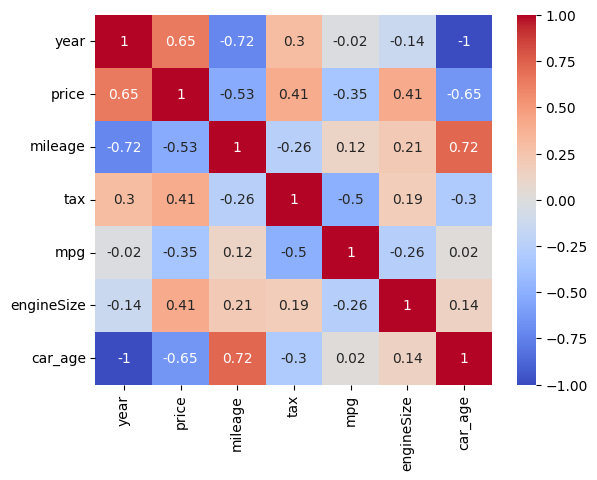

In [27]:
sns.heatmap(corr,annot=True,cmap="coolwarm")

In [28]:
x=df.drop(columns=['price','year'])
y=df['price']

In [29]:
x.shape

(17811, 8)

In [30]:
y.shape

(17811,)

In [31]:
x.ndim

2

In [32]:
y.ndim

1

In [33]:
df.columns

Index(['model', 'year', 'price', 'transmission', 'mileage', 'fuelType', 'tax',
       'mpg', 'engineSize', 'car_age'],
      dtype='object')

In [34]:
x=pd.get_dummies(x,columns=["model","transmission","fuelType"],drop_first=True)

In [35]:
x.shape

(17811, 34)

In [36]:
x.head()

,mileage,tax,mpg,engineSize,car_age,model_ C-MAX,model_ EcoSport,model_ Edge,model_ Escort,model_ Fiesta,...,model_ Tourneo Connect,model_ Tourneo Custom,model_ Transit Tourneo,model_Focus,transmission_Manual,transmission_Semi-Auto,fuelType_Electric,fuelType_Hybrid,fuelType_Other,fuelType_Petrol
0,15944,150,57.7,1.0,3,False,False,False,False,True,...,False,False,False,False,False,False,False,False,False,True
1,9083,150,57.7,1.0,2,False,False,False,False,False,...,False,False,False,False,True,False,False,False,False,True
2,12456,150,57.7,1.0,3,False,False,False,False,False,...,False,False,False,False,True,False,False,False,False,True
3,10460,145,40.3,1.5,1,False,False,False,False,True,...,False,False,False,False,True,False,False,False,False,True
4,1482,145,48.7,1.0,1,False,False,False,False,True,...,False,False,False,False,False,False,False,False,False,True


In [37]:
x=x.astype(int)

In [38]:
x.head()

,mileage,tax,mpg,engineSize,car_age,model_ C-MAX,model_ EcoSport,model_ Edge,model_ Escort,model_ Fiesta,...,model_ Tourneo Connect,model_ Tourneo Custom,model_ Transit Tourneo,model_Focus,transmission_Manual,transmission_Semi-Auto,fuelType_Electric,fuelType_Hybrid,fuelType_Other,fuelType_Petrol
0,15944,150,57,1,3,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,1
1,9083,150,57,1,2,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,1
2,12456,150,57,1,3,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,1
3,10460,145,40,1,1,0,0,0,0,1,...,0,0,0,0,1,0,0,0,0,1
4,1482,145,48,1,1,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,1


In [39]:
from sklearn.preprocessing import StandardScaler

In [40]:
scaler=StandardScaler()

In [41]:
nums=['mileage','tax','mpg','car_age','engineSize']
x[nums]=scaler.fit_transform(x[nums])
x

,mileage,tax,mpg,engineSize,car_age,model_ C-MAX,model_ EcoSport,model_ Edge,model_ Escort,model_ Fiesta,...,model_ Tourneo Connect,model_ Tourneo Custom,model_ Transit Tourneo,model_Focus,transmission_Manual,transmission_Semi-Auto,fuelType_Electric,fuelType_Hybrid,fuelType_Other,fuelType_Petrol
0,-0.382920,0.591483,-0.042378,-0.446973,-0.069100,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,1
1,-0.736260,0.591483,-0.042378,-0.446973,-0.562581,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,1
2,-0.562551,0.591483,-0.042378,-0.446973,-0.069100,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,1
3,-0.665344,0.510877,-1.720342,-0.446973,-1.056062,0,0,0,0,1,...,0,0,0,0,1,0,0,0,0,1
4,-1.127709,0.510877,-0.930712,-0.446973,-1.056062,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17961,-0.343986,0.591483,-1.029415,-0.446973,-0.069100,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,1
17962,0.892007,-1.343040,-0.042378,-0.446973,1.411343,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,1
17963,-0.843019,-1.504251,0.944660,-0.446973,0.917862,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0
17964,-0.946172,0.510877,-0.042378,-0.446973,-0.562581,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,1


In [42]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=30)

In [43]:
x_test.shape

(3563, 34)

In [44]:
from sklearn.linear_model import LinearRegression


In [45]:
model=LinearRegression()

In [46]:
model.fit(x_train,y_train)

LinearRegression()

In [47]:
pred=model.predict(x_test)

In [48]:
from sklearn.metrics import r2_score,mean_squared_error,mean_absolute_error

In [49]:
r2_score_result=r2_score(y_test,pred)
print(r2_score_result)

0.8509586639225049


In [50]:
mse_result=mean_squared_error(y_test,pred)
print(mse_result)

3412981.8812879953


In [51]:
rmse_result=np.sqrt(mse_result)
mean_y=np.mean(y_test)
per=mean_y*0.1
print(rmse_result)
print(per)

1847.425744458487
1224.5891664327814
